<h1>CME538 - Introduction to Data Science</h1><h2>Lecture 7.1 - Classification I</h2><p>Week 6 fitted numerical outcomes. Here the target is a category. We build a model of the probability of class 1, choose a loss for those probabilities, and fit its parameters. Central question: How do features become a fitted probability of an outcome?</p><p>You will distinguish scores from probabilities, compare losses, trace gradient updates, and interpret fitted outputs.</p><h3>Lecture Structure</h3><ol><li><a href="#section1">Regression on Probabilities</a></li><li><a href="#section2">The Logistic Model</a></li><li><a href="#section3">Logistic Loss Function</a></li><li><a href="#section4">Fitting a Logistic Model</a></li><li><a href="#section5">Scikit-Learn</a></li></ol><p><a href="#summary">Lecture summary</a></p><h3>Sources and documentation</h3><p><a href="DATA_SOURCES.md">Data descriptions and attribution</a>. <a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html">LogisticRegression</a>. <a href="https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html">Pipelines</a>. <a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.log_loss.html">Cross-entropy with log_loss</a>.</p>

<h2>Setup Notebook</h2><p>Run the prepared cells in order in the course environment. The <a href="requirements.txt">dependency list</a> records the required packages. All examples use local data. Plot layout and display helpers live in <code>utils.py</code>. The methods being taught remain visible.</p>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import log_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import utils

RANDOM_STATE = 538
rng = np.random.default_rng(RANDOM_STATE)
utils.configure_plots()

<a id="section1"></a><h2>1. Regression on Probabilities</h2><p>Question: Why does fitting a straight line to a binary outcome create a problem?</p>

<h3>1.1 Define the target</h3><p>A target label records the outcome of interest. Each row records one LeBron shot attempt in the 2017 NBA playoffs. Here class 1 means a made shot and class 0 means a missed shot. The recorded label is our reference for fitting and evaluation. A different task needs a different label definition.</p>

In [2]:
shots = pd.read_csv('lebron.csv')
X = shots[['shot_distance']]
y = shots['shot_made'].to_numpy()
display(shots[['shot_distance', 'shot_made']].head())
print('Recorded shots:', len(shots))

,shot_distance,shot_made
0,0,0
1,0,1
2,0,1
3,0,1
4,0,1


Recorded shots: 384


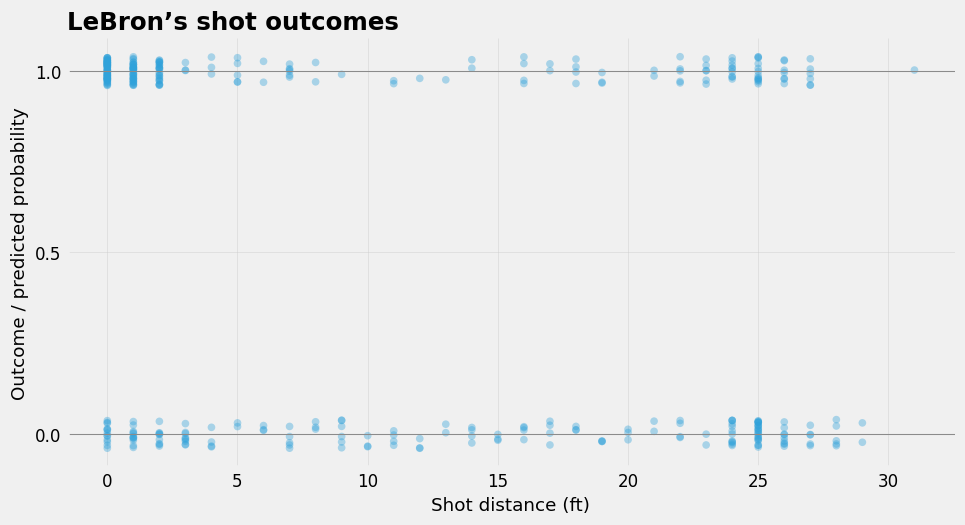

In [3]:
utils.shot_plot(X.shot_distance, y)

<p>The small vertical jitter separates overlapping observations. Outcomes remain binary. The plot suggests a lower success rate at longer distances, with both makes and misses at many distances.</p>

<h3>1.2 A straight-line probability model</h3><p>Fit a line to the 0/1 target to expose a limitation. This is a descriptive fit to the observed shots, without a claim about future accuracy.</p>

In [4]:
linear = LinearRegression().fit(X, y)
distances = pd.DataFrame({'shot_distance': [0, 15, 30, 100]})
display(distances.assign(prediction=linear.predict(distances)).round(3))

,shot_distance,prediction
0,0,0.715
1,15,0.505
2,30,0.294
3,100,-0.690


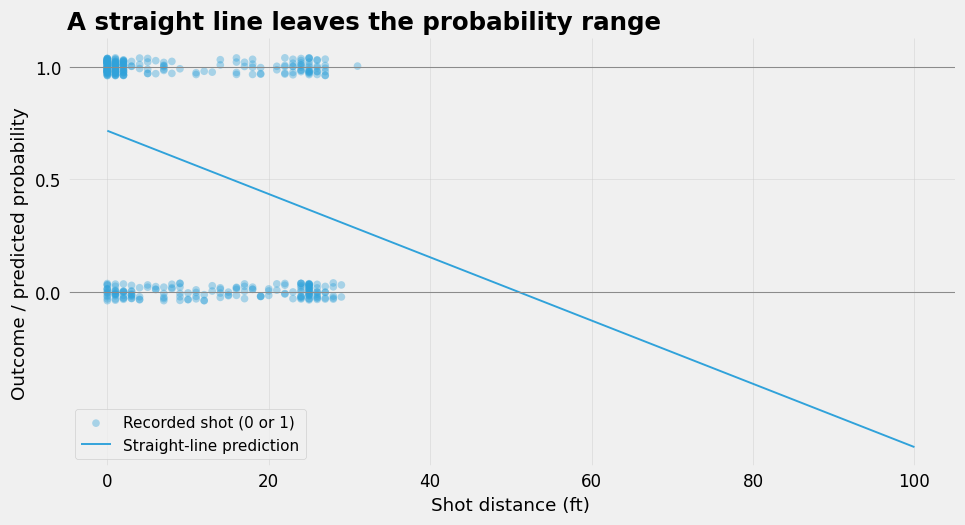

In [5]:
shot_grid = np.linspace(0, 100, 300)
grid_frame = pd.DataFrame({'shot_distance': shot_grid})
utils.shot_plot(X.shot_distance, y, shot_grid,
                {'Straight-line prediction': linear.predict(grid_frame)},
                title='A straight line leaves the probability range', probability=False)

<p>Takeaway: A probability must lie between 0 and 1. The fitted line has no such restriction. We need a model form with a bounded probability output.</p>

<a id="section2"></a><h2>2. The Logistic Model</h2><p>Question: How do we convert a linear score into a probability?</p>

<h3>2.1 The sigmoid</h3><p>The linear score is z = θ₀ + θ₁x. The sigmoid converts the score to a value strictly between 0 and 1: p = 1 / (1 + exp(−z)). A score of 0 gives p = 0.5. Positive scores give higher probabilities.</p>

In [6]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.array([-4, -1, 0, 1, 4])
display(pd.DataFrame({"Score z": z, "Probability": sigmoid(z)}).round(3))

,Score z,Probability
0,-4,0.018
1,-1,0.269
2,0,0.500
3,1,0.731
4,4,0.982


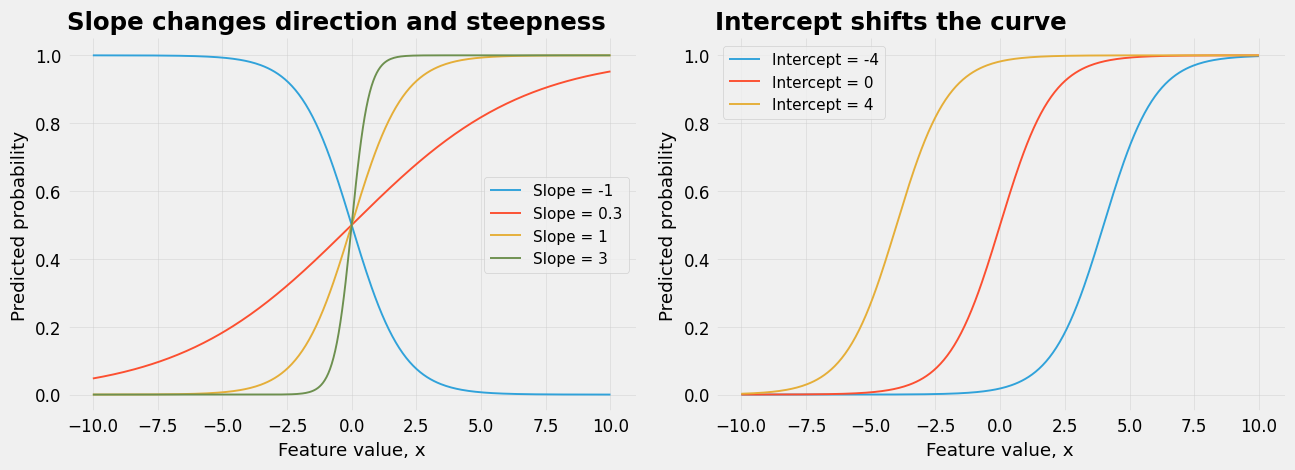

In [7]:
utils.sigmoid_parameters(np.linspace(-10, 10, 300))

<p>A positive slope makes probability increase with x. A negative slope reverses the direction. The intercept changes the location of the curve. The horizontal axis shows the feature x, before calculating the linear score.</p>

<h3>2.2 Equal score changes</h3><p>Compare an increase of one score unit near the middle with the same increase in the upper tail.</p>

In [8]:
intervals = pd.DataFrame({'Start': [-1, 3], 'End': [0, 4]})
intervals['Probability change'] = sigmoid(intervals.End) - sigmoid(intervals.Start)
display(intervals.round(3))

,Start,End,Probability change
0,-1,0,0.231
1,3,4,0.029


<p>Takeaway: The sigmoid converts a linear score to a probability. The sigmoid is most sensitive near its middle. The same score change has a smaller probability effect near 0 or 1. We next need a loss to compare those probabilities with the recorded outcomes.</p>

<a id="section3"></a><h2>3. Logistic Loss Function</h2><p>Question: How should the loss distinguish uncertain mistakes from confident mistakes?</p>

<h3>3.1 Cross-entropy for one observation</h3><p>For an actual positive, loss = −ln(p). For an actual negative, loss = −ln(1 − p). The combined expression is L = −[y ln(p) + (1 − y) ln(1 − p)]. Here p is the predicted probability of class 1 and y is its recorded label.</p>

In [9]:
p = np.array([0.4, 0.1])
display(pd.DataFrame({'Probability for a known positive': p,
                      'Cross-entropy loss': -np.log(p)}).round(3))

print('Mean cross-entropy:',
      round(log_loss([1, 1], p, labels=[0, 1]), 3))

,Probability for a known positive,Cross-entropy loss
0,0.4,0.916
1,0.1,2.303


Mean cross-entropy: 1.609


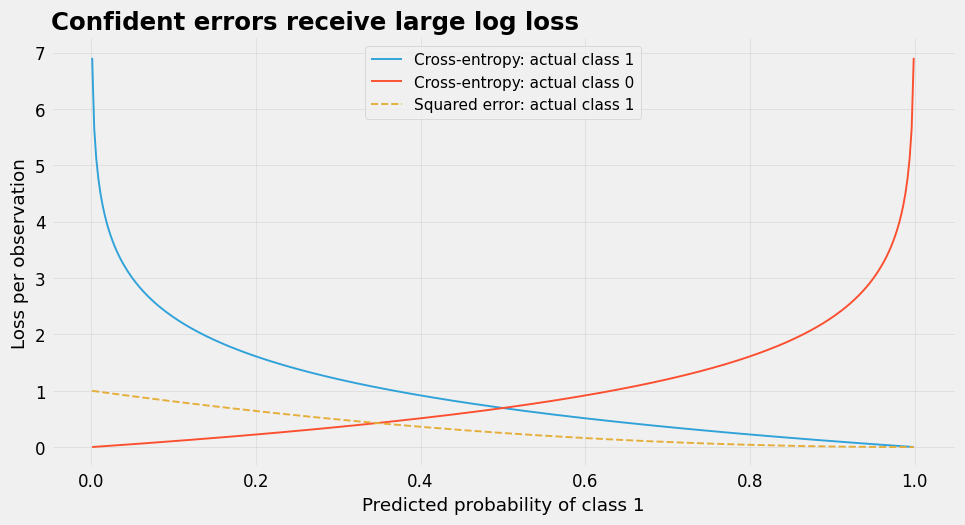

In [10]:
p_grid = np.linspace(0.001, 0.999, 400)
utils.loss_curves(p_grid, -np.log(p_grid), -np.log(1-p_grid), (1-p_grid)**2)

<p>Both probabilities in the table fall below 0.5, so both would produce the wrong class at this threshold. The probability 0.1 receives the larger loss. Fitting uses the probabilities, without applying a decision threshold.</p><p>Scikit-learn calls this metric <code>log_loss</code>. Pass the recorded labels first and the predicted probabilities second. The result is the mean cross-entropy. We specify <code>labels=[0, 1]</code> because this small example contains only actual positives.</p>

<h3>3.2 Loss as parameters change</h3><p>We now move from individual shots to NBA game outcomes. Does a team that shoots more accurately than its opponent tend to win? The feature FG_PCT_DIFF is the team’s field-goal proportion minus its opponent’s. For example, 0.10 means 50% compared with 40%, a difference of 10 percentage points. WON is 1 for a win and 0 for a loss.</p><p>Each completed game contributes two team rows: one winner and one loser. We join the final box scores to calculate the difference. These features describe completed games; they are not available before tip-off. We use this same dataset for the loss plots, gradient descent and scikit-learn.</p>

In [11]:
nba = pd.read_csv('nba.csv')
paired = nba.merge(nba, on='GAME_ID', suffixes=('', '_OPP'))
paired = paired.loc[paired.TEAM_ID != paired.TEAM_ID_OPP].copy()
games = pd.DataFrame({
    'GAME_ID': paired.GAME_ID,
    'FG_PCT_DIFF': paired.FG_PCT - paired.FG_PCT_OPP,
    'WON': (paired.WL == 'W').astype(int),
})
assert games.groupby('GAME_ID').size().eq(2).all()
x = games.FG_PCT_DIFF.to_numpy()
game_y = games.WON.to_numpy()
display(games.head())
print('Team observations:', len(games), '| Games:', games.GAME_ID.nunique())

,GAME_ID,FG_PCT_DIFF,WON
1,21700002,0.053,0
2,21700002,-0.053,1
5,21700001,-0.049,0
6,21700001,0.049,1
9,21700011,-0.026,0


Team observations: 2460 | Games: 1230


<p>A loss plotted against probability differs from a loss plotted against model parameters. Hold the intercept at zero and vary the slope to compare the two losses. Standardizing the shooting difference keeps the parameter scale convenient for gradient descent.</p>

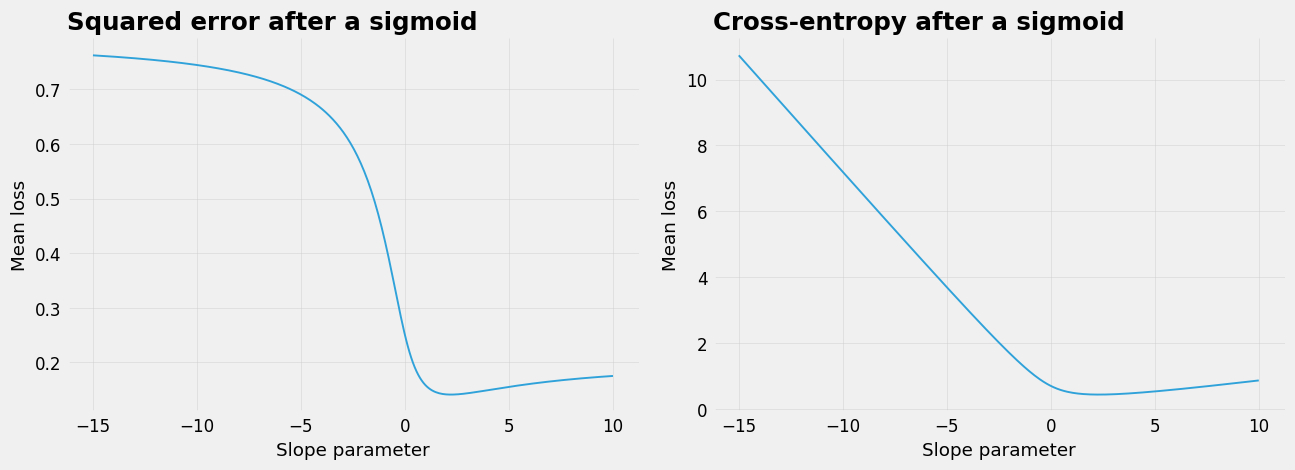

In [12]:
x_mean = x.mean()
x_scale = x.std(ddof=0)
x_scaled = (x - x_mean) / x_scale
slopes = np.linspace(-15, 10, 300)
probability_grid = sigmoid(x_scaled[:, None] * slopes)
mse_values = ((game_y[:, None] - probability_grid)**2).mean(axis=0)
score_grid = x_scaled[:, None] * slopes
log_loss_values = (np.logaddexp(0, score_grid) - game_y[:, None]*score_grid).mean(axis=0)
utils.loss_landscape(slopes, mse_values, log_loss_values)

<p>Takeaway: Cross-entropy gives a convex objective for a logistic model with a linear score. Convexity rules out inferior local minima, but does not by itself guarantee unique finite parameters. The demonstration has an overlapping pair of classes and a finite fitted solution. We now use gradient descent to find the fitted parameters.</p>

<a id="section4"></a><h2>4. Fitting a Logistic Model</h2><p>Question: How do gradient updates fit the probability curve?</p>

<h3>4.1 Calculate the gradient</h3><p>We reuse the Week 5 update: subtract the learning rate times the gradient. With a column of ones for the intercept, the average gradient is Xᵀ(p − y) / n. Here y is the recorded win/loss label, stored in game_y. Each update compares the current win probabilities with those labels.</p><p>The two gradient components are the average probability error for the intercept and the average of the standardized shooting difference times probability error for the slope. The loop records each parameter pair for the animation below.</p>

In [13]:
design = np.column_stack([np.ones(len(game_y)), x_scaled])
theta = np.zeros(2)
learning_rate = 0.2
loss_history = []
theta_history = [theta.copy()]

for step in range(1500):
    scores = design @ theta
    probabilities = sigmoid(scores)
    loss = np.mean(np.logaddexp(0, scores) - game_y * scores)
    gradient = design.T @ (probabilities - game_y) / len(game_y)
    loss_history.append(loss)
    theta = theta - learning_rate * gradient
    theta_history.append(theta.copy())

print("Fitted intercept and slope:", theta.round(4))
print("Initial / final loss:", round(loss_history[0], 4), round(loss_history[-1], 4))

Fitted intercept and slope: [-0.      2.3074]
Initial / final loss: 0.6931 0.4296


<p>Press Play to follow the same updates. The left plot shows the current win-probability curve and the curve after the next update. The middle plot traces the parameters across contours of equal loss. The arrow points from the current parameters to the next pair. The right panel substitutes the gradient values into the update equation.</p><p>Update 0 is the starting point, before any fitting. Playback shows every early update, then skips ahead as the changes shrink. Drag Updates to inspect any of the 1,500 updates. Reset returns to the starting point, and Final fit shows the final recorded parameters.</p><p>Blue dots are the recorded team outcomes: 1 for a win and 0 for a loss. Transparency helps show overlapping observations. Their positions stay fixed while the probability curve changes.</p>

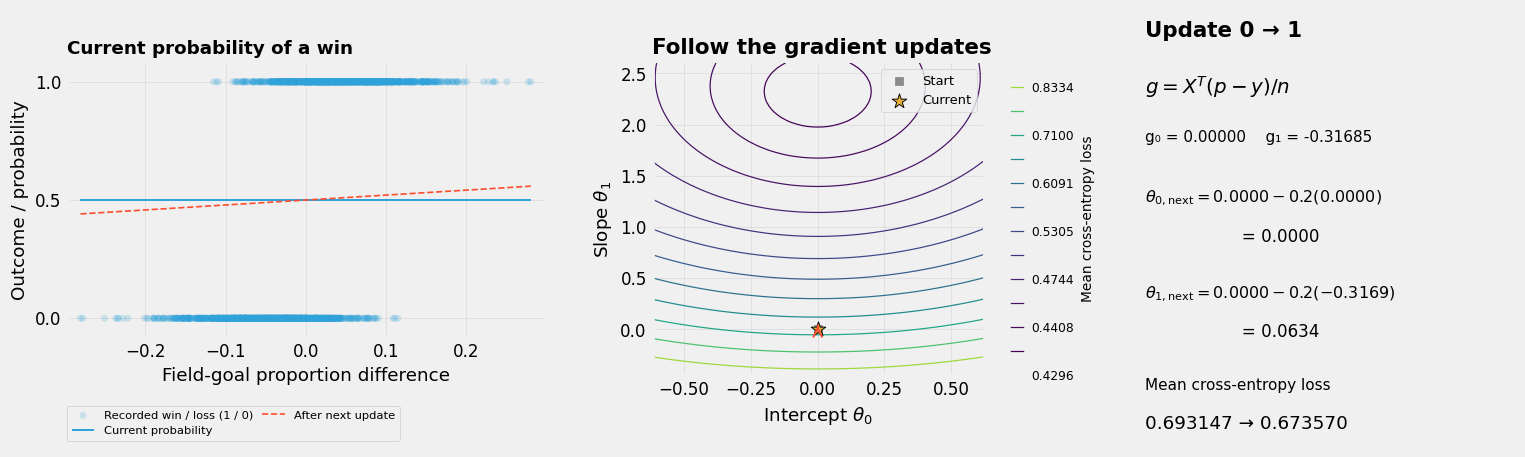

In [14]:
gradient_animation = utils.logistic_gradient_widget(
    x, game_y, theta_history, learning_rate, x_mean, x_scale,
    xlabel='Field-goal proportion difference',
    outcome_label='Recorded win / loss (1 / 0)',
    curve_title='Current probability of a win'
)

<p>At the start, every team receives probability 0.5. The slope gradient is about −0.3169. Subtracting 0.2 times that value increases the slope from 0 to 0.0634, so the curve begins to give teams with a shooting advantage a higher win probability.</p><p>Each game supplies a winner and a loser with opposite feature values. This symmetry keeps the intercept at zero. The model uses the standardized feature when calculating gradients, while the probability plot shows the original proportion difference. Outcomes remain at 0 or 1. The loss history below shows the loss before each update.</p>

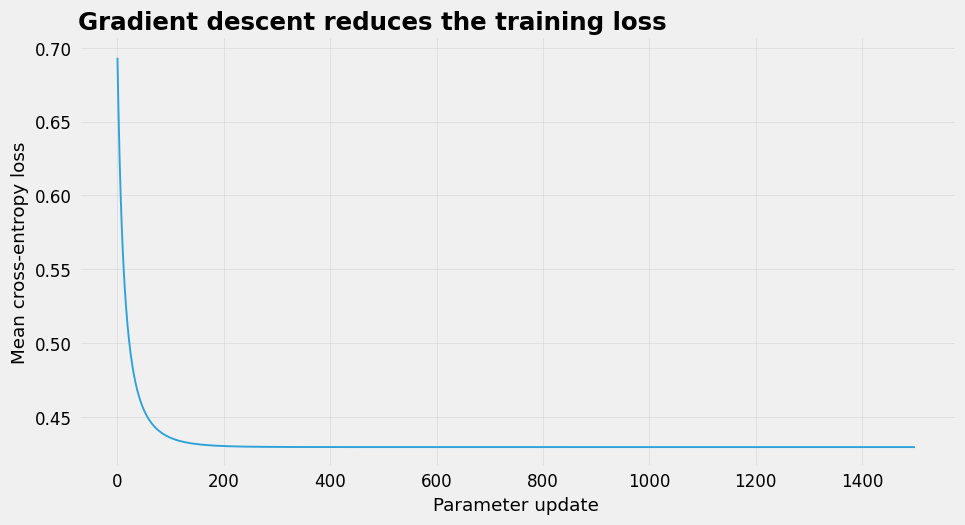

In [15]:
utils.training_history(loss_history)

<h3>4.2 Interpret the fitted curve</h3><p>Convert each shooting difference to the standardized scale used in training, then apply the fitted score and sigmoid. The fitted curve rises from near 0 to near 1 across the observed range. Around equal shooting accuracy, small differences have a larger effect on the model’s probability than they do near either end of the curve.</p><p>A difference of −0.10 gives a fitted win probability of about 0.045; 0 gives 0.50; and +0.10 gives about 0.955. The overlapping wins and losses show that shooting accuracy alone does not determine the result. Small vertical jitter in the plot separates overlapping points; the recorded outcomes are still 0 or 1.</p>

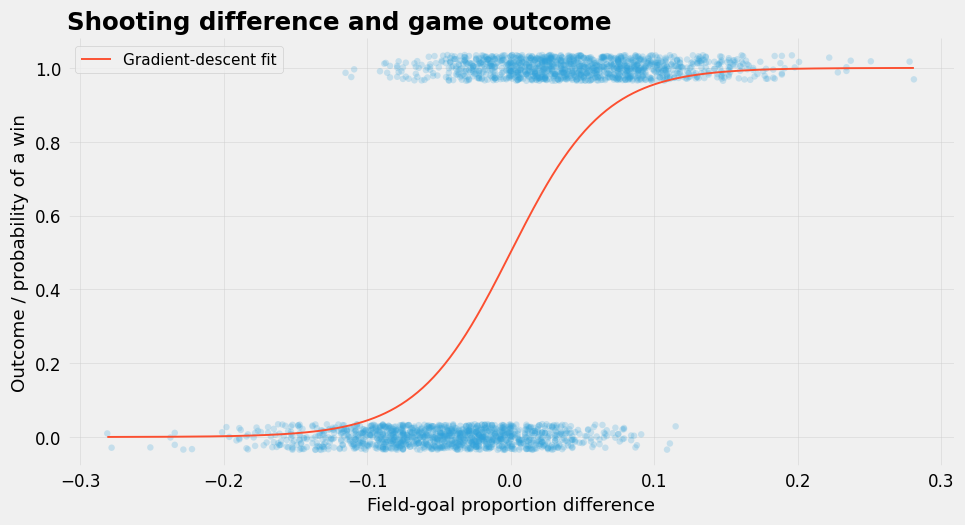

In [16]:
game_grid = np.linspace(x.min(), x.max(), 300)
fitted_probability = sigmoid(theta[0] + theta[1]*(game_grid-x_mean)/x_scale)
utils.nba_probability(games, game_grid, fitted_probability,
                      label='Gradient-descent fit', show_threshold=False)

<p>Takeaway: Gradient descent turns a flat starting probability into a fitted sigmoid by reducing cross-entropy loss. This is a description of the training games. Evaluation on new games is a separate step. Next, we check the same fitted probabilities through the scikit-learn estimator API.</p>

<a id="section5"></a><h2>5. Scikit-Learn</h2><p>Question: How does the estimator API express the same fitting workflow?</p>

<h3>5.1 Fit the game model with scikit-learn</h3><p>Use a pipeline to combine <code>StandardScaler</code> with <code>LogisticRegression</code>. Calling <code>fit</code> learns the feature mean and scale, transforms the input, and fits the logistic model. Later predictions reuse the fitted transformation, so we pass shooting differences in their original units.</p><p>The <code>lbfgs</code> solver minimizes the logistic loss using a different numerical optimizer from our gradient-descent loop. A coefficient penalty discourages large coefficient values during fitting. <code>C=1e6</code> makes this penalty negligible when comparing with the manual loop. Week 8 explains coefficient penalties.</p>

In [17]:
game_features = games[['FG_PCT_DIFF']]
game_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1e6, solver='lbfgs', max_iter=2000, tol=1e-10)
)
game_model.fit(game_features, game_y)

api_probability = game_model.predict_proba(game_features)[:, 1]
gd_probability = sigmoid(design @ theta)
print('Probability column order:', game_model.classes_)
print('Training cross-entropy:', round(log_loss(game_y, api_probability), 4))
print('Largest probability difference:', f'{np.max(np.abs(api_probability-gd_probability)):.2e}')

Probability column order: [0 1]
Training cross-entropy: 0.4296
Largest probability difference: 8.23e-08


<p><code>predict_proba</code> returns one column for each entry in <code>classes_</code>. Here the order is [0, 1], so <code>[:, 1]</code> selects the probability of a win. The two fits agree to within 0.000001 in their probabilities for these training observations. The <code>log_loss</code> call measures the same mean cross-entropy used in the loop. These checks concern the training fit. Evaluation on new games comes later.</p><h3>5.2 From probabilities to class predictions</h3><p>Keep the fitted pipeline fixed and predict for three shooting differences. <code>predict_proba</code> returns probabilities and <code>predict</code> returns class labels. The pipeline applies its fitted scaler automatically in both calls.</p>

In [18]:
examples = pd.DataFrame({'FG_PCT_DIFF': [-0.1, 0, 0.1]})
examples['Probability of win'] = game_model.predict_proba(examples[['FG_PCT_DIFF']])[:, 1]
examples['Predicted class'] = game_model.predict(examples[['FG_PCT_DIFF']])

display(examples.round(3))

,FG_PCT_DIFF,Probability of win,Predicted class
0,-0.1,0.045,0
1,0.0,0.500,0
2,0.1,0.955,1


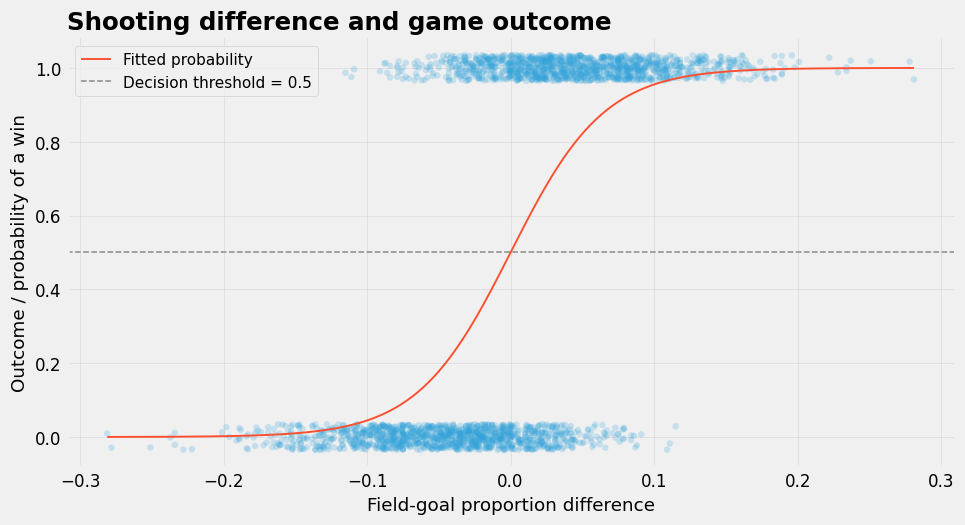

In [19]:
game_grid_frame = pd.DataFrame({'FG_PCT_DIFF': game_grid})
game_probability = game_model.predict_proba(game_grid_frame)[:, 1]
utils.nba_probability(games, game_grid, game_probability)

<p>A difference of 0.1 means 10 percentage points, such as 50% compared with 40%. The horizontal line marks probability 0.5, the default decision boundary. The equal-shooting case is at this boundary, so a numerical rounding difference can change its class label without meaningfully changing its probability. Lecture 7.2 separates probabilities from decision thresholds and evaluates the decisions on validation games.</p>

<p>Takeaway: Use a pipeline to keep preprocessing and the classifier together. The estimator API separates fitting, probability prediction and class prediction. Use <code>log_loss</code> to calculate cross-entropy from those probabilities. Both team rows from the same game must stay together when we evaluate on held-out games.</p>

<a id="summary"></a><h2>Lecture summary</h2><ul><li>Define class 1 before fitting or calculating a metric.</li><li>The sigmoid maps a linear score to a probability.</li><li>Cross-entropy distinguishes mistakes by their confidence.</li><li>Gradient descent fits parameters through explicit updates.</li><li>A probability needs a decision rule before it becomes a class prediction.</li></ul>